[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%BE%A4%E7%B5%84%E8%B3%87%E6%96%99%E5%92%8C%E7%BE%A4%E7%B5%84%E9%81%8B%E7%AE%97/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E6%8D%B7%E9%81%8B%E5%93%AA%E4%B8%80%E7%AB%99%E6%9C%80%E6%93%A0_%E8%AA%B0%E4%BD%8F%E9%80%99%E8%A3%A1%E8%AA%B0%E5%9C%A8%E9%80%99%E4%B8%8A%E7%8F%AD.ipynb)

# 🚇 捷運哪一站最擠？誰住這裡、誰在這裡上班？

> 🎯 **情境**：每天早上擠捷運的你，有沒有想過：**哪一站最多人？大家都從哪裡出發、去哪裡上班？假日大家又去哪裡玩？**臺北捷運公開了每一站、每一小時的進出站人次——一個月就有 8 萬列。只要學會一招 **groupby（分組 → 計算 → 合併）**，就能從這堆數字裡看出整座城市的作息。

| 素材檔案 | 內容 |
| --- | --- |
| `臺北捷運各站分時進出量_202603.csv` | 臺北捷運 2026 年 3 月，每一站、每一天、每一小時的進站與出站人次（約 8 萬列；由臺北捷運公司的起訖站資料彙總） |

| 📡 資料來源（政府資料開放平台） | 提供機關 | 下載日期 |
| --- | --- | --- |
| [臺北捷運各站分時進出量統計](https://data.gov.tw/dataset/128506) | 臺北大眾捷運股份有限公司 | 2026-10-24 |

> ✅ 這些都是**真實的政府開放資料**，依「政府資料開放授權條款－第1版」使用。課堂上統一使用上表日期的快照，所以每個人跑出來的數字都一樣。

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 先檢查站名——同一站怎麼有兩個名字？ |
| ⬜ 任務 2 | 哪一站最擠？——各站成績單 |
| ⬜ 任務 3 | 平日和假日，大家搭捷運的時間一樣嗎？ |
| ⬜ 任務 4 | 誰住這裡？誰在這裡上班？——先加總，再相除 |
| ⬜ 任務 5 | `pd.cut`——把每一站分成「住宅型、混合型、上班型」 |
| ⬜ 任務 6 | 樞紐分析表——假日大家都去哪裡？ |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「你想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '臺北捷運各站分時進出量_202603.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%BE%A4%E7%B5%84%E8%B3%87%E6%96%99%E5%92%8C%E7%BE%A4%E7%B5%84%E9%81%8B%E7%AE%97/%E7%BE%A4%E7%B5%84%E8%B3%87%E6%96%99%E5%92%8C%E7%BE%A4%E7%B5%84%E9%81%8B%E7%AE%97_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['臺北捷運各站分時進出量_202603.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：先檢查站名——同一站怎麼有兩個名字？

**白話說明**：分組之前，**分組用的欄位一定要乾淨**，不然同一組會被拆成兩組。我們先數一數每一站有幾列、進站和出站各多少。

In [3]:
import pandas as pd

mrt = pd.read_csv('臺北捷運各站分時進出量_202603.csv', parse_dates=['日期'])
print(mrt.shape, '，車站數：', mrt['車站'].nunique())
display(mrt.head())

check_names = mrt.groupby('車站')[['進站人次', '出站人次']].sum()
check_names[check_names.index.str.contains('板橋|大坪林|景安|頭前庄')]

(79422, 5) ，車站數： 122


,日期,時段,車站,進站人次,出站人次
0,2026-03-01,0,BL板橋,241,156
1,2026-03-01,0,G大坪林,0,142
2,2026-03-01,0,O景安,0,134
3,2026-03-01,0,O頭前庄,0,24
4,2026-03-01,0,Y板橋,45,0


,進站人次,出站人次
車站,,
BL板橋,1194523,1308163
G大坪林,0,605826
O景安,0,642184
O頭前庄,0,158363
Y板橋,78792,0
大坪林,634404,0
景安,687623,0
頭前庄,170454,0


> 🕵️ **發現問題**：「大坪林」只有進站、出站是 0；出站人次都記在「G大坪林」！板橋也被拆成「BL板橋」和「Y板橋」。
> 這些是**轉乘站**：資料把不同路線的紀錄，用「路線代碼＋站名」分開記。要分析「這一站」有多少人，得先把開頭的英文代碼去掉、合成同一站。

In [4]:
mrt['車站'] = mrt['車站'].str.replace(r'^[A-Z]+', '', regex=True)      # 去掉開頭的英文路線代碼：G大坪林 → 大坪林
mrt = mrt.groupby(['日期', '時段', '車站'], as_index=False)[['進站人次', '出站人次']].sum()   # 同一站的紀錄加起來
mrt['假日'] = mrt['日期'].dt.day_of_week >= 5                           # 星期六、日
print('統一站名後的車站數：', mrt['車站'].nunique())
mrt[mrt['車站'] == '大坪林'].head(3)

統一站名後的車站數： 118


,日期,時段,車站,進站人次,出站人次,假日
43,2026-03-01,0,大坪林,45,142,True
161,2026-03-01,1,大坪林,3,7,True
279,2026-03-01,5,大坪林,1,1,True


## 任務 2：哪一站最擠？——各站成績單

**白話說明**：「依 ___ 分組，計算 ___ 的 ___」。`agg` 可以一次算好幾個統計量，並取中文欄名：`新欄名=('原欄位', '計算方式')`。

In [5]:
days = mrt['日期'].nunique()
station = mrt.groupby('車站').agg(進站=('進站人次', 'sum'), 出站=('出站人次', 'sum'))
station['每日平均進出'] = ((station['進站'] + station['出站']) / days).round(0)
station.sort_values('每日平均進出', ascending=False).head(10)

,進站,出站,每日平均進出
車站,,,
台北車站,4813670,4721788,307595.0
西門,2177892,2208529,141497.0
市政府,1880079,1989856,124837.0
中山,1612523,1674478,106032.0
忠孝復興,1368065,1362645,88087.0
南京復興,1255931,1329071,83387.0
板橋,1273315,1308163,83273.0
新埔,1179428,1174854,75945.0
松江南京,1142475,1184942,75078.0


> 💡 **看懂結果**：台北車站每天平均有 30 多萬人次進出，是第二名的兩倍以上——它同時是捷運兩條線、台鐵、高鐵、機場捷運的交會點。

## 任務 3：平日和假日，大家搭捷運的時間一樣嗎？

**白話說明**：用**兩個欄位**分組：「假日 × 時段」。`unstack` 把「假日」搬到欄位，變成一張「時段 × 平日／假日」的表，方便畫圖比較。因為平日和假日的天數不一樣，要除以天數才是「平均每天」。

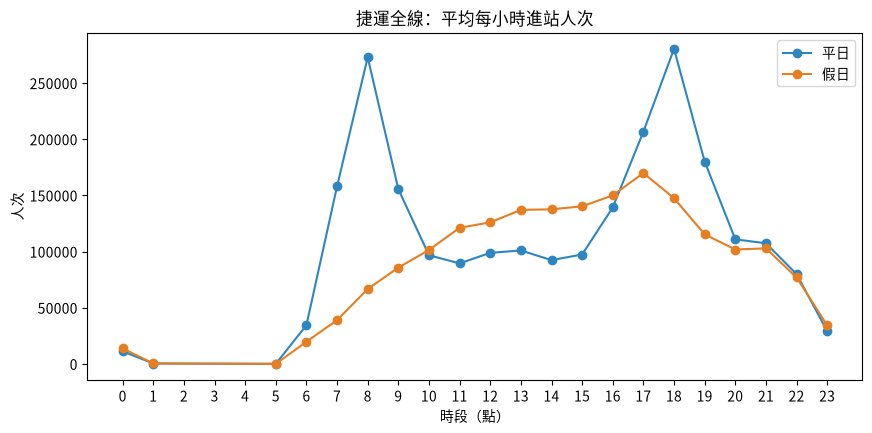

In [6]:
import matplotlib.pyplot as plt

n_days = mrt.groupby('假日')['日期'].nunique()                          # 平日幾天、假日幾天
by_hour = mrt.groupby(['假日', '時段'])['進站人次'].sum().unstack('假日') / n_days   # 平均每天、每小時
by_hour.columns = ['平日', '假日']

ax = by_hour.plot(figsize=(10, 4.5), marker='o', color=['#2E86C1', '#E67E22'],
                  title='捷運全線：平均每小時進站人次')
ax.set_xticks(range(0, 24)); ax.set_xlabel('時段（點）'); ax.set_ylabel('人次')
plt.show()

> 💡 **看懂結果**：平日是「**雙峰**」：早上 8 點、傍晚 6 點兩個尖峰——標準的上班上學作息；假日只有一個平緩的「**午後山丘**」，大家睡飽才出門。

## 任務 4：誰住這裡？誰在這裡上班？——先加總，再相除

**白話說明**：平日早上 7～9 點，
- **住宅區**：大家從家裡出發 → **進站多、出站少**。
- **上班區**：大家到公司報到 → **出站多、進站少**。

所以「早上出站 ÷ 進站」越大，越像上班區。⚠️ 比率一定要**先把人次加總，再相除**，不能把每小時的比率直接平均。

In [7]:
morning = mrt[(~mrt['假日']) & (mrt['時段'].between(7, 8))]               # 平日 7:00～8:59
am = morning.groupby('車站')[['進站人次', '出站人次']].sum()               # 先加總
am = am[am.sum(axis=1) > 100_000]                                         # 只看人比較多的站
am['出站÷進站'] = (am['出站人次'] / am['進站人次']).round(2)               # 再相除

print('🏠 最像「住宅區」的站（早上幾乎只有人出發）：')
display(am.sort_values('出站÷進站').head(6))
print('🏢 最像「上班區」的站（早上大家都來這裡）：')
display(am.sort_values('出站÷進站', ascending=False).head(6))

🏠 最像「住宅區」的站（早上幾乎只有人出發）：


,進站人次,出站人次,出站÷進站
車站,,,
蘆洲,168019,12186,0.07
南勢角,195207,16080,0.08
三重國小,102495,12761,0.12
徐匯中學,114763,14292,0.12
景安,196438,30000,0.15
三和國中,126776,19809,0.16


🏢 最像「上班區」的站（早上大家都來這裡）：


,進站人次,出站人次,出站÷進站
車站,,,
台大醫院,18138,200107,11.03
松江南京,46206,396115,8.57
善導寺,29881,192748,6.45
台北小巨蛋,34690,195325,5.63
西湖,28730,146274,5.09
南京復興,76992,363034,4.72


> 💡 **看懂結果**：蘆洲、南勢角這些站，早上進站的人是出站的 10 倍以上——**大家住這裡**；台大醫院、松江南京、善導寺則反過來，出站是進站的好幾倍——**大家在這裡上班、看病**。
> 一個簡單的比率，就畫出了整座城市的「住」與「工作」地圖。
>
> 🤖 **換你問 AI**：「我有捷運各站每小時的進出站人次。請篩選平日早上 7～9 點，依車站加總進站與出站，再計算出站÷進站，找出最像住宅區和最像商辦區的車站。」

## 任務 5：`pd.cut`——把每一站分成「住宅型、混合型、上班型」

**白話說明**：`pd.cut` 把連續的數字切成幾個區間，再貼上標籤。切點自己決定：比率 < 0.5 算住宅型、0.5～2 算混合型、> 2 算上班型。

In [8]:
am['類型'] = pd.cut(am['出站÷進站'], bins=[0, 0.5, 2, 100], labels=['🏠 住宅型', '🔀 混合型', '🏢 上班型'])
am['類型'].value_counts()

類型
🔀 混合型    30
🏠 住宅型    26
🏢 上班型    26
Name: count, dtype: int64

## 任務 6：樞紐分析表——假日大家都去哪裡？

**白話說明**：`pivot_table` 就是 Excel 的樞紐分析表：列放「車站」、欄放「假日」、值放「進站人次」、計算方式是「加總」。再除以天數，就能比較「假日平均每天」和「平日平均每天」。

In [9]:
pivot = mrt.pivot_table(index='車站', columns='假日', values='進站人次', aggfunc='sum') / n_days
pivot.columns = ['平日每天', '假日每天']
pivot['假日÷平日'] = (pivot['假日每天'] / pivot['平日每天']).round(2)
pivot[pivot['平日每天'] > 8_000].sort_values('假日÷平日', ascending=False).head(8).round({'平日每天': 0, '假日每天': 0})

,平日每天,假日每天,假日÷平日
車站,,,
大安森林公園,10837.0,17336.0,1.60
國父紀念館,26783.0,34449.0,1.29
圓山,28914.0,36216.0,1.25
西門,66998.0,78215.0,1.17
三重,10891.0,12662.0,1.16
台北車站,148242.0,172483.0,1.16
中山,49899.0,57193.0,1.15
淡水,34773.0,35585.0,1.02


> 💡 **看懂結果**：假日人潮暴增的是**大安森林公園**（約 1.6 倍）、**國父紀念館**、**圓山**（花博公園、美術館）——公園、展覽、觀光景點。
> 反過來，假日人最少的多半是商辦區。**同一條捷運，平日載上班族，假日載去玩的人。**

<details><summary>🔄 想看最新資料？點我</summary>

臺北捷運每個月都會公布新的資料。這裡可以查到每個月原始檔的網址：

```python
import pandas as pd
index = pd.read_csv('https://data.taipei/api/dataset/63f31c7e-7fc3-418b-bd82-b95158755b4d/resource/eb481f58-1238-4cff-8caa-fa7bb20cb4f4/download')
index.tail()        # 每個月一個原始檔的下載網址（一個月約 300MB 的起訖站資料，下載前請確認網路與硬碟空間）
```

> ⚠️ 開放資料的欄位偶爾會改名或調整，如果最新資料跑出錯誤，正好練習看懂錯誤訊息、對照欄位名稱修正程式。

</details>

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [10]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：星期幾搭捷運的人最多？

<details><summary>💡 卡住了？點我看提示</summary>

先用 `.dt.day_of_week` 做出星期幾（0 = 星期一），再「依星期分組、加總進站人次」，最後除以「每個星期幾各有幾天」才公平。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
mrt['星期'] = mrt['日期'].dt.___
weekday_total = mrt.groupby('星期')['進站人次'].sum()
weekday_days = mrt.groupby('星期')['日期'].nunique()
weekday_avg = weekday_total / weekday_days
display(weekday_avg.round(0))
print('平均每天最多人的是星期', weekday_avg.idxmax() + 1)

In [ ]:
# @title ✅ 執行這格，檢查練習 1
_wd = mrt['日期'].dt.day_of_week
check('weekday_avg', mrt.groupby(_wd)['進站人次'].sum() / mrt.groupby(_wd)['日期'].nunique())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
mrt['星期'] = mrt['日期'].dt.day_of_week
weekday_total = mrt.groupby('星期')['進站人次'].sum()
weekday_days = mrt.groupby('星期')['日期'].nunique()
weekday_avg = weekday_total / weekday_days
display(weekday_avg.round(0))
print('平均每天最多人的是星期', weekday_avg.idxmax() + 1)
```

</details>

### ✍️ 練習 2：平日的台北車站，哪一個小時最多人出站？

<details><summary>💡 卡住了？點我看提示</summary>

先篩出「台北車站」而且「不是假日」，再依「時段」分組加總出站人次，最後 `idxmax()`。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
tpe = mrt[(mrt['車站'] == ___) & (~mrt['假日'])]
tpe_peak = tpe.groupby(___)['出站人次'].sum().idxmax()
print('平日台北車站出站最多的時段：', tpe_peak, '點')

In [ ]:
# @title ✅ 執行這格，檢查練習 2
_t = mrt[(mrt['車站'] == '台北車站') & (~mrt['假日'])]
check('tpe_peak', _t.groupby('時段')['出站人次'].sum().idxmax())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
tpe = mrt[(mrt['車站'] == '台北車站') & (~mrt['假日'])]
tpe_peak = tpe.groupby('時段')['出站人次'].sum().idxmax()
print('平日台北車站出站最多的時段：', tpe_peak, '點')
```

</details>

### ✍️ 練習 3：每一站「單日進站最多」是哪一天、幾人次？

<details><summary>💡 卡住了？點我看提示</summary>

先「依車站、日期分組加總」得到每站每天的進站人次；再「依車站分組」用 `agg(['max', 'idxmax'])` 或分兩步做。這裡用 `max` 就好。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
daily = mrt.groupby(['車站', '日期'])['進站人次'].sum()
busiest = daily.groupby(level=___).max().sort_values(ascending=False)
display(busiest.head(5))

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('busiest', mrt.groupby(['車站', '日期'])['進站人次'].sum().groupby(level='車站').max())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
daily = mrt.groupby(['車站', '日期'])['進站人次'].sum()
busiest = daily.groupby(level='車站').max().sort_values(ascending=False)
display(busiest.head(5))
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：先檢查站名——同一站怎麼有兩個名字？
- ✅ 任務 2：哪一站最擠？——各站成績單
- ✅ 任務 3：平日和假日，大家搭捷運的時間一樣嗎？
- ✅ 任務 4：誰住這裡？誰在這裡上班？——先加總，再相除
- ✅ 任務 5：`pd.cut`——把每一站分成「住宅型、混合型、上班型」
- ✅ 任務 6：樞紐分析表——假日大家都去哪裡？

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以拿去報告的分析。